# 06 — Price impact and the price-taker question

Two questions:

1. **What happened to spreads as batteries connected?** An event study around each battery's first full operating month, with a previous-year control.
2. **Would a new 100 MW battery be a price taker?** The local slope of price against dispatched quantity, estimated from the data.

The second question would normally be answered from offer curves. Post-reform Real-Time Market Submissions are participant-only: `effective-balancing-submission` stops at September 2023 and the post-reform submissions are available through WEMS and its API, which this project does not use (assumption D3). So the slope is **estimated**, not observed, by first-differencing consecutive dispatch intervals — differencing removes anything that moves slowly relative to five minutes, which is most confounders. Every number below carries that caveat.

This notebook reads `outputs/backcast_summary.csv` rather than rebuilding the fleet, so it runs in seconds. Run `scripts/run_backcast.py` first.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import price_impact, viz
from src.paths import OUTPUTS

viz.use_style()
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

metrics = price_impact.daily_metrics()
print(f"{len(metrics):,} trading days of price metrics")
metrics.head(3).round(2)

1,128 trading days of price metrics


,spread,mean_price,negative_share,capturable_spread_2h,contingency_raise_price,contingency_lower_price,regulation_raise_price,regulation_lower_price,rocof_price,fcess_price_sum
trading_date,,,,,,,,,,
2023-10-01,594.99,60.44,0.19,261.54,80.11,110.36,44.81,91.01,0.0,326.3
2023-10-02,346.45,56.16,0.31,242.43,73.11,60.80,16.15,75.85,0.0,225.9
2023-10-03,636.01,60.71,0.19,329.81,43.65,26.66,10.30,55.99,0.0,136.6


## When did each battery start operating?

From the backcast: the first month in which the facility cleared the commissioning threshold on most trading days. The rating is the observed peak injection, not the registered MW, which for a storage facility counts the full bidirectional range (assumption D8).

In [2]:
events = price_impact.commissioning_dates_from_summary()
capacity = price_impact.cumulative_storage_capacity_from_summary()
capacity.round(1)

C:\Users\james\AppData\Local\Temp\ipykernel_47252\1370763662.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  capacity.round(1)


,facility_code,from,rating_mw,usable_mwh,cumulative_mw,cumulative_mwh
0,KWINANA_ESR1,2024-01-01,100.7,197.2,100.7,197.2
1,COLLIE_ESR1,2024-10-01,200.0,852.9,300.6,1050.1
2,KWINANA_ESR2,2025-04-01,226.4,959.5,527.0,2009.6
3,COLLIE_BESS2,2025-08-01,300.1,1279.3,827.1,3288.9
4,COLLIE_ESR4,2026-01-01,252.0,1066.1,1079.1,4355.0
5,COLLIE_ESR5,2026-01-01,252.7,1066.1,1331.8,5421.1
6,ALINTA_WGP_ESR1,2026-08-01,101.0,211.9,1432.7,5633.0


## Capacity against spread

The headline relationship. A correlation over three years is suggestive, not causal — demand, fuel costs and the rest of the generation fleet all moved too — but the size of the move is hard to explain any other way.

In [3]:
joint = price_impact.capacity_against_spread(metrics, capacity)
joint.round(2).tail(12)

,capturable_spread_2h,spread,fcess_price_sum,negative_share,operating_storage_mw,operating_storage_mwh
trading_date,,,,,,
2025-12-01,81.59,93.73,15.29,0.0,827.06,3288.91
2026-01-01,64.90,86.41,11.45,0.0,1331.76,5421.11
2026-02-01,61.86,81.24,11.98,0.0,1331.76,5421.11
2026-03-01,41.35,55.03,9.36,0.0,1331.76,5421.11
2026-04-01,30.18,38.62,2.05,0.0,1331.76,5421.11
2026-05-01,74.56,87.62,5.47,0.0,1331.76,5421.11
2026-06-01,96.85,135.94,0.66,0.0,1331.76,5421.11
2026-07-01,97.94,144.22,0.17,0.0,1331.76,5421.11
2026-08-01,102.44,141.34,0.45,0.0,1432.72,5633.02


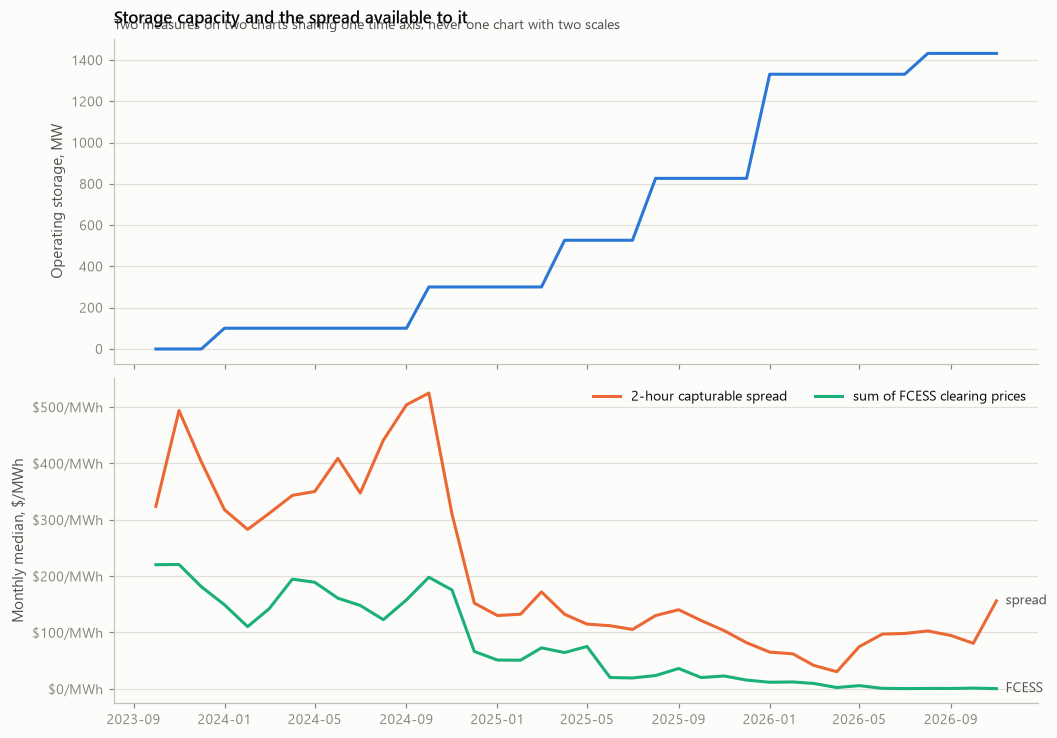

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.6), sharex=True, layout="constrained")
fig.patch.set_facecolor(viz.SURFACE)
for ax in axes:
    ax.set_facecolor(viz.SURFACE)

axes[0].plot(joint.index, joint["operating_storage_mw"], color=viz.SERIES[0])
axes[0].set_ylabel("Operating storage, MW")
viz.finish(
    axes[0],
    "Storage capacity and the spread available to it",
    subtitle="Two measures on two charts sharing one time axis, never one chart with two scales",
)

axes[1].plot(
    joint.index, joint["capturable_spread_2h"], color=viz.SERIES[1], label="2-hour capturable spread"
)
axes[1].plot(
    joint.index, joint["fcess_price_sum"], color=viz.SERIES[2], label="sum of FCESS clearing prices"
)
viz.label_last(axes[1], joint.index[-1], joint["capturable_spread_2h"].iloc[-1], "spread", viz.SERIES[1])
viz.label_last(axes[1], joint.index[-1], joint["fcess_price_sum"].iloc[-1], "FCESS", viz.SERIES[2])
viz.money(axes[1], unit="/MWh")
axes[1].set_ylabel("Monthly median, $/MWh")
axes[1].legend(loc="upper right", ncols=2)
plt.show()

In [5]:
correlations = joint.corr(method="spearman")["operating_storage_mw"].drop(
    ["operating_storage_mw", "operating_storage_mwh"]
)
print("Spearman rank correlation with operating storage capacity")
print(correlations.round(3).to_string())
print(f"\nmonths observed: {len(joint)}")
print(
    "\nA rank correlation over 37 months of a market undergoing rapid structural change\n"
    "is suggestive, not causal. It is reported because the magnitude is large, not\n"
    "because the sample supports an identification claim."
)

Spearman rank correlation with operating storage capacity
capturable_spread_2h   -0.854
spread                 -0.846
fcess_price_sum        -0.935
negative_share         -0.764

months observed: 38

A rank correlation over 37 months of a market undergoing rapid structural change
is suggestive, not causal. It is reported because the magnitude is large, not
because the sample supports an identification claim.


## Event study

Median metrics in the 90 days before and after each battery's first full operating month, with the same calendar window a year earlier as a control. If the before-to-after change is similar in the control window, the change is seasonal rather than caused by the entrant.

In [6]:
study = price_impact.event_study(metrics, events, window_days=90)
study[
    [
        "capturable_spread_2h before",
        "capturable_spread_2h after",
        "capturable_spread_2h change",
        "fcess_price_sum change",
    ]
].round(1)

capturable_spread_2h before  capturable_spread_2h after  capturable_spread_2h change  fcess_price_sum change
facility_code   window                                                                                                                     
ALINTA_WGP_ESR1 event                                 88.8                        94.1                          5.3                    -0.2
                previous year                        110.2                       127.1                         16.9                    -0.8
COLLIE_BESS2    event                                110.2                       127.1                         16.9                    -0.8
                previous year                        350.6                       499.6                        149.0                    -3.3
COLLIE_ESR1     event                                423.0                       267.2                       -155.8                   -14.1
                previous year                        261.5                       408.0                        146.4                  -111.5
COLLIE_ESR4     event                                102.7                        56.3                        -46.5                    -7.3
                previous year                        263.5                       146.7                       -116.8                   -74.6
COLLIE_ESR5     event                                102.7                        56.3                        -46.5                    -7.3
                previous year                        263.5                       146.7                       -116.8                   -74.6
KWINANA_ESR1    event                                408.0                       299.9                       -108.1                   -72.7
KWINANA_ESR2    event                                146.7                       118.6                        -28.1                     3.1
                previous year                        299.9                       366.1                         66.2                    45.4

In [7]:
pivot = study["capturable_spread_2h change"].unstack("window")
if "previous year" in pivot.columns:
    pivot["difference in differences"] = pivot["event"] - pivot["previous year"]
print("change in the 2-hour capturable spread, $/MWh")
pivot.round(1)

change in the 2-hour capturable spread, $/MWh


window,event,previous year,difference in differences
facility_code,,,
ALINTA_WGP_ESR1,5.3,16.9,-11.6
COLLIE_BESS2,16.9,149.0,-132.1
COLLIE_ESR1,-155.8,146.4,-302.2
COLLIE_ESR4,-46.5,-116.8,70.3
COLLIE_ESR5,-46.5,-116.8,70.3
KWINANA_ESR1,-108.1,NaN,NaN
KWINANA_ESR2,-28.1,66.2,-94.3


## Would a new 100 MW battery be a price taker?

The regression is of the change in settlement price between consecutive dispatch intervals on the change in dispatched energy requirement over the same pair, estimated separately in each price band. The band that matters for discharging is the top decile; the band that matters for charging is the bottom.

In [8]:
slopes = price_impact.estimate_supply_slope()
verdict = price_impact.price_taker_verdict(slopes)
verdict.round(4)

,band,price range,slope $/MWh per MW,standard error,t,r squared,intervals,"impact of 100 MW, $/MWh",band midpoint $/MWh,impact as share of level,price taker
0,lowest decile (charging),"-1,000 to -7",0.1058,0.0067,15.7445,0.0097,25411,10.5750,-503.5,0.0210,True
1,middle,-7 to 145,0.0434,0.0012,34.8815,0.0060,203253,4.3435,69.0,0.0629,False
2,highest decile (discharging),"145 to 1,100",0.1994,0.0130,15.3336,0.0092,25410,19.9439,622.5,0.0320,True
3,all intervals,"-1,000 to 1,100",0.0749,0.0019,39.6888,0.0062,254057,7.4948,50.0,0.1499,False


In [9]:
by_year = []
for year in (2024, 2025, 2026):
    estimate = price_impact.estimate_supply_slope(f"{year}-01-01", f"{year}-12-31")
    estimate["year"] = year
    by_year.append(estimate)

yearly = pd.concat(by_year, ignore_index=True)
print("estimated price move from adding 100 MW, $/MWh")
yearly.pivot_table(
    index="band", columns="year", values="impact of 100 MW, $/MWh", observed=True
).round(2)

estimated price move from adding 100 MW, $/MWh


year,2024,2025,2026
band,,,
all intervals,14.36,5.02,1.55
highest decile (discharging),37.42,11.46,4.43
lowest decile (charging),16.37,4.00,1.17
middle,8.85,3.61,1.11


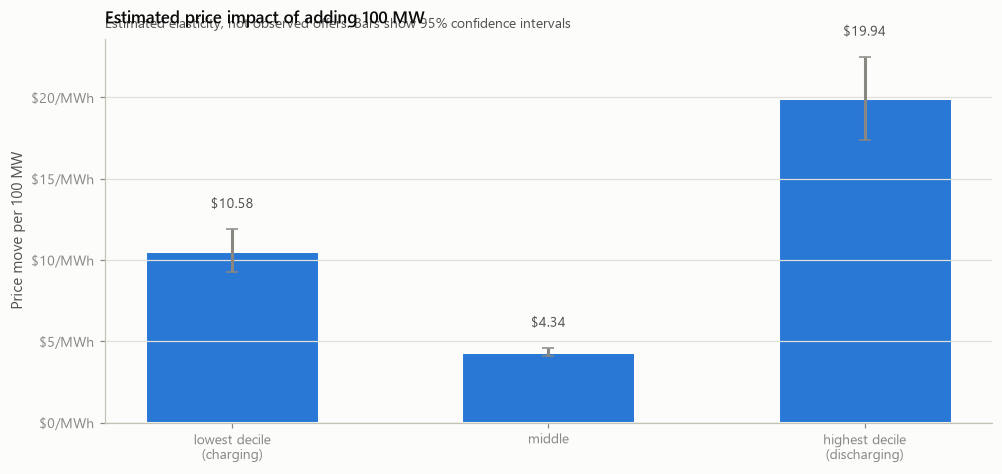

In [10]:
fig, ax = viz.figure(9.0, 4.2)

bands = [b for b in verdict["band"] if b != "all intervals"]
x = np.arange(len(bands))
impacts = [verdict.loc[verdict["band"] == b, "impact of 100 MW, $/MWh"].iloc[0] for b in bands]
errors = [verdict.loc[verdict["band"] == b, "standard error"].iloc[0] * 100 * 1.96 for b in bands]

bars = ax.bar(
    x, impacts, yerr=errors, capsize=4, color=viz.SERIES[0], width=0.55,
    linewidth=2, edgecolor=viz.SURFACE, ecolor=viz.INK_MUTED,
)
ax.bar_label(bars, fmt="$%.2f", padding=12, fontsize=9, color=viz.INK_SECONDARY)

ax.axhline(0, color=viz.AXIS, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([b.replace(" (", "\n(") for b in bands])
viz.money(ax, unit="/MWh")
viz.finish(
    ax,
    "Estimated price impact of adding 100 MW",
    subtitle="Estimated elasticity, not observed offers. Bars show 95% confidence intervals",
    ylabel="Price move per 100 MW",
)
plt.show()

## The revenue haircut

A battery that moves the price pays for it twice: it charges into a slightly higher price and discharges into a slightly lower one. Applying the estimated impact in both directions gives the share of the capturable spread a 100 MW entrant would erode.

In [11]:
low_band = verdict[verdict["band"].str.contains("charging")].iloc[0]
high_band = verdict[verdict["band"].str.contains("discharging")].iloc[0]
erosion = abs(low_band["impact of 100 MW, $/MWh"]) + abs(high_band["impact of 100 MW, $/MWh"])

annual_spread = metrics["capturable_spread_2h"].resample("YS").median()
haircut = pd.DataFrame(
    {
        "median capturable spread $/MWh": annual_spread,
        "estimated erosion $/MWh": erosion,
        "haircut share of spread": erosion / annual_spread,
    }
)
haircut.index = haircut.index.year
haircut.round(3)

,median capturable spread $/MWh,estimated erosion $/MWh,haircut share of spread
trading_date,,,
2023,403.759,30.519,0.076
2024,350.214,30.519,0.087
2025,119.702,30.519,0.255
2026,73.245,30.519,0.417


In [12]:
OUTPUTS.mkdir(parents=True, exist_ok=True)
verdict.to_csv(OUTPUTS / "price_impact_slopes.csv", index=False)
yearly.to_csv(OUTPUTS / "price_impact_slopes_by_year.csv", index=False)
haircut.to_csv(OUTPUTS / "price_impact_haircut.csv")
joint.to_csv(OUTPUTS / "capacity_against_spread.csv")
study.to_csv(OUTPUTS / "price_impact_event_study.csv")
print("written to outputs/")

written to outputs/


## Verdict

Read the haircut table against the capture rates in notebook 04. If the erosion is a small share of the capturable spread, a 100 MW entrant is close enough to a price taker that the revenue estimates stand. If it is large, those estimates are optimistic by roughly that share, and sensitivity case PI-1 in `scripts/run_sensitivities.py` carries the haircut through to the NPV.